# Config B — Thử nhóm thời tiết dạng số

## Mục tiêu

Kiểm tra xem thêm bốn biến thời tiết dạng số vào Config A có giảm MAE hay không. Dùng B đầy đủ làm mốc để xem việc giữ thêm các cột nhãn thời tiết ảnh hưởng thế nào đến sai số.

- **A** có 12 đặc trưng thời gian và ngày lễ.
- **A + thời tiết dạng số** có 16 đặc trưng. Bốn cột thêm là `temp_c`, `rain_1h`, `snow_1h` và `clouds_all`.
- **B đầy đủ** có 27 đặc trưng, gồm 16 cột của phương án trên và 11 cột nhãn thời tiết.

Cả ba phương án dùng cùng bộ tham số Random Forest đã chốt ngày 16/11, cùng dữ liệu và mốc chia. Chọn theo MAE trung bình qua 3 fold thời gian. Xem thêm RMSE và MAE giờ cao điểm theo cờ `is_rush_hour` của dự án.

## Params

In [15]:
EXPERIMENT_NAME = "17-11-2026_ConfigB_WeatherNumeric_Phuc"
MODEL_NAME = "Random Forest"
TARGET = "traffic_volume"
CV_SPLITS = 3
PRIMARY_METRIC = "MAE"
RUN_VALIDATION = True

DATA_PARAMS = {"mask_stuck_temp": False, "complete_holidays": False}

MODEL_PARAMS = {
    "n_estimators": 400,
    "max_depth": 12,
    "min_samples_leaf": 5,
    "max_features": 1.0,
    "random_state": 42,
    "n_jobs": -1,
}

## Import và tìm thư mục dự án

In [16]:
import json
import sys
import warnings
from pathlib import Path
from datetime import datetime, timezone, timedelta
from time import perf_counter

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import TimeSeriesSplit


def find_project_root():
    current = Path.cwd().resolve()

    for folder in (current, *current.parents):
        for candidate in (
            folder,
            folder / "metro_interstate_traffic_volume",
        ):
            if (
                (candidate / "src" / "models.py").is_file()
                and (candidate / "src" / "features.py").is_file()
            ):
                return candidate

    raise FileNotFoundError(
        "Không tìm thấy dự án. Hãy kiểm tra thư mục làm việc của kernel."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src import features
from src.data import fill_missing_weather, load_hourly_splits
from src.evaluation import clip_prediction, regression_metrics

DATA_PATH = PROJECT_ROOT / "data" / "Metro_Interstate_Traffic_Volume.csv"

RUN_ID = datetime.now(
    timezone(timedelta(hours=7))
).strftime("%Y%m%d_%H%M%S_%f")

OUTPUT_DIR = (
    PROJECT_ROOT
    / "experiments"
    / EXPERIMENT_NAME
    / "outputs"
    / RUN_ID
)

print("Project:", PROJECT_ROOT)
print("Data:", DATA_PATH)
print("Output:", OUTPUT_DIR)

assert DATA_PATH.is_file(), f"Không tìm thấy dữ liệu: {DATA_PATH}"
REFERENCE_DIR = PROJECT_ROOT / "experiments" / "13-11-2026_ConfigB_4Model_Phuc"

# Nạp lại pipeline Random Forest đã dùng ở các thí nghiệm trước của Phúc.
import importlib.util
spec = importlib.util.spec_from_file_location(
    "config_b_grid_cv", REFERENCE_DIR / "config_b_grid_cv.py"
)
grid_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(grid_module)
make_config_b_pipeline = grid_module.make_config_b_pipeline

Project: D:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume
Data: D:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\data\Metro_Interstate_Traffic_Volume.csv
Output: D:\SGU_HocMay_2026-2027\metro_interstate_traffic_volume\experiments\17-11-2026_ConfigB_WeatherNumeric_Phuc\outputs\20261117_141557_451140


## Đọc dữ liệu và khai báo các nhóm đặc trưng

In [17]:
CONFIG_FEATURES = {
    "A": list(features.CONFIG_A),
    "A_numeric": [*features.CONFIG_A, *features.WEATHER_NUMERIC_FEATURES],
    "B": list(features.CONFIG_B),
}

assert [len(columns) for columns in CONFIG_FEATURES.values()] == [12, 16, 27]
assert set(CONFIG_FEATURES["A_numeric"]) < set(CONFIG_FEATURES["B"])
assert set(CONFIG_FEATURES["A_numeric"]) - set(CONFIG_FEATURES["A"]) == {
    "temp_c", "rain_1h", "snow_1h", "clouds_all",
}
assert set(CONFIG_FEATURES["B"]).isdisjoint([TARGET, *features.HISTORY_FEATURES])

splits = load_hourly_splits(path=DATA_PATH, **DATA_PARAMS)
raw_train = splits["train"]
raw_validation = splits["validation"]

for frame in (raw_train, raw_validation):
    assert not frame.empty
    assert frame["date_time"].is_monotonic_increasing
    assert not frame["date_time"].duplicated().any()

assert raw_train["date_time"].max() < raw_validation["date_time"].min()

display(pd.DataFrame([
    {"config": name, "n_features": len(columns), "features": ", ".join(columns)}
    for name, columns in CONFIG_FEATURES.items()
]))
display(pd.DataFrame([
    {
        "split": name,
        "rows": len(frame),
        "start": frame["date_time"].min(),
        "end": frame["date_time"].max(),
    }
    for name, frame in (("train", raw_train), ("validation", raw_validation))
]))

,config,n_features,features
0,A,12,"hour, day_of_week, month, is_weekend, is_rush_..."
1,A_numeric,16,"hour, day_of_week, month, is_weekend, is_rush_..."
2,B,27,"hour, day_of_week, month, is_weekend, is_rush_..."


,split,rows,start,end
0,train,28402,2012-10-02 09:00:00,2017-05-10 04:00:00
1,validation,6086,2017-05-10 05:00:00,2018-01-19 14:00:00


## Chuẩn bị fold và hàm tính điểm

Tính thống kê điền thiếu thời tiết từ phần train của mỗi fold. Chuẩn bị chung một bộ dữ liệu cho ba phương án, rồi chọn cột trước khi fit. Dùng thời tiết quan sát cùng giờ với lưu lượng cần dự đoán.

In [18]:
def prepare_pair(fit_rows, score_rows):
    parts = fill_missing_weather({
        "train": fit_rows.copy(),
        "validation": score_rows.copy(),
    })
    train = features.add_weather_features(features.add_time_features(parts["train"]))
    score = features.add_weather_features(features.add_time_features(parts["validation"]))
    return train, score


def fit_and_score(train, score, feature_columns):
    pipeline = make_config_b_pipeline(MODEL_NAME, MODEL_PARAMS)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        start = perf_counter()
        pipeline.fit(train[feature_columns], train[TARGET])
        fit_seconds = perf_counter() - start

        start = perf_counter()
        raw_prediction = pipeline.predict(score[feature_columns])
        predict_seconds = perf_counter() - start

    assert np.isfinite(raw_prediction).all()
    prediction = clip_prediction(raw_prediction)
    metrics = regression_metrics(score[TARGET], prediction)
    rush = score["is_rush_hour"].eq(1).to_numpy()
    rush_mae = float(np.mean(np.abs(score[TARGET].to_numpy()[rush] - prediction[rush]))) if rush.any() else np.nan

    row = {
        "model": MODEL_NAME,
        "n_features": len(feature_columns),
        "n_train": len(train),
        "n_score": len(score),
        "n_rush_hours": int(rush.sum()),
        "fit_seconds": fit_seconds,
        "predict_seconds": predict_seconds,
        **metrics,
        "MAE_rush": rush_mae,
        "warnings": " | ".join(dict.fromkeys(str(w.message) for w in caught)),
    }
    return row, raw_prediction, prediction

## So sánh theo 3 fold thời gian

Ba phương án dùng chung các fold train, tổng cộng 9 lần fit. Đọc bảng tổng hợp theo MAE, sau đó xem bảng từng fold để kiểm tra chênh lệch. Cột `delta_MAE_vs_B` âm nghĩa là MAE thấp hơn B đầy đủ.

In [19]:
fold_rows = []
splitter = TimeSeriesSplit(n_splits=CV_SPLITS)
for fold, (fit_idx, score_idx) in enumerate(splitter.split(raw_train), start=1):
    train, score = prepare_pair(raw_train.iloc[fit_idx], raw_train.iloc[score_idx])
    for config, columns in CONFIG_FEATURES.items():
        print(f"Fold {fold}/{CV_SPLITS} · {config}", flush=True)
        row, _, _ = fit_and_score(train, score, columns)
        fold_rows.append({
            "config": config,
            "fold": fold,
            "fit_end": train["date_time"].max(),
            "score_start": score["date_time"].min(),
            "score_end": score["date_time"].max(),
            **row,
        })

cv_scores = pd.DataFrame(fold_rows)
cv_summary = (
    cv_scores.groupby("config", sort=False)
    .agg(
        n_features=("n_features", "first"),
        mean_MAE=("MAE", "mean"),
        std_MAE=("MAE", lambda scores: scores.std(ddof=0)),
        mean_RMSE=("RMSE", "mean"),
        mean_R2=("R2", "mean"),
        mean_MAE_rush=("MAE_rush", "mean"),
    )
    .sort_values(f"mean_{PRIMARY_METRIC}", kind="stable")
)
cv_summary["delta_MAE_vs_B"] = cv_summary["mean_MAE"] - cv_summary.loc["B", "mean_MAE"]
display(cv_summary.round(4))
display(cv_scores.pivot(index="config", columns="fold", values="MAE").round(4))

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
cv_scores.to_csv(OUTPUT_DIR / "cv_fold_scores.csv", index=False)
cv_summary.to_csv(OUTPUT_DIR / "cv_summary.csv")
(OUTPUT_DIR / "run_config.json").write_text(
    json.dumps({
        "dataset": str(DATA_PATH.relative_to(PROJECT_ROOT)),
        "data_params": DATA_PARAMS,
        "cv_splits": CV_SPLITS,
        "primary_metric": PRIMARY_METRIC,
        "model": MODEL_NAME,
        "model_params": MODEL_PARAMS,
        "features": CONFIG_FEATURES,
    }, indent=2),
    encoding="utf-8",
)

Fold 1/3 · A
Fold 1/3 · A_numeric
Fold 1/3 · B
Fold 2/3 · A
Fold 2/3 · A_numeric
Fold 2/3 · B
Fold 3/3 · A
Fold 3/3 · A_numeric
Fold 3/3 · B


,n_features,mean_MAE,std_MAE,mean_RMSE,mean_R2,mean_MAE_rush,delta_MAE_vs_B
config,,,,,,,
A,12,280.6167,24.0021,461.3954,0.9452,411.4923,-0.6673
B,27,281.2840,21.5292,467.1493,0.9438,412.3340,0.0000
A_numeric,16,282.0660,22.3908,468.9245,0.9433,413.8997,0.7821


fold,1,2,3
config,,,
A,254.7463,274.5206,312.5833
A_numeric,266.3711,266.0959,313.7310
B,266.8307,265.3031,311.7181


1567

## Đánh giá trên validation

Sau khi xem CV, đặt `RUN_VALIDATION=True` trong cell Params, chạy lại cell Params rồi chạy hai cell bên dưới. Fit lại cả ba phương án trên toàn bộ train để so trên cùng các giờ validation. Dùng kết quả CV để chọn phương án và bảng validation để đối chiếu với A và B.

In [20]:
if RUN_VALIDATION:
    train, validation = prepare_pair(raw_train, raw_validation)
    predictions = validation[["date_time", TARGET, "is_rush_hour"]].copy()
    metric_rows = []
    for config, columns in CONFIG_FEATURES.items():
        print(f"Đang chạy validation: {config}", flush=True)
        row, raw_prediction, prediction = fit_and_score(train, validation, columns)
        metric_rows.append({"config": config, "split": "validation", **row})
        predictions[f"{config}__raw"] = raw_prediction
        predictions[config] = prediction

    validation_results = pd.DataFrame(metric_rows).set_index("config")
    validation_results["delta_MAE_vs_B"] = (
        validation_results["MAE"] - validation_results.loc["B", "MAE"]
    )
    display(validation_results.round(4))
    validation_results.to_csv(OUTPUT_DIR / "validation_metrics.csv")
    predictions.to_csv(OUTPUT_DIR / "validation_predictions.csv", index=False)
else:
    print("Validation đang tắt. Bật RUN_VALIDATION sau khi xem kết quả CV.")

Đang chạy validation: A
Đang chạy validation: A_numeric
Đang chạy validation: B


,split,model,n_features,n_train,n_score,n_rush_hours,fit_seconds,predict_seconds,MAE,RMSE,R2,MAE_rush,warnings,delta_MAE_vs_B
config,,,,,,,,,,,,,,
A,validation,Random Forest,12,28402,6086,1091,1.3735,0.1174,241.9691,380.9411,0.9624,360.5882,,1.8711
A_numeric,validation,Random Forest,16,28402,6086,1091,2.9043,0.1044,242.2687,397.2135,0.9592,359.7013,,2.1706
B,validation,Random Forest,27,28402,6086,1091,3.2794,0.1255,240.0981,395.4852,0.9595,354.0912,,0.0000


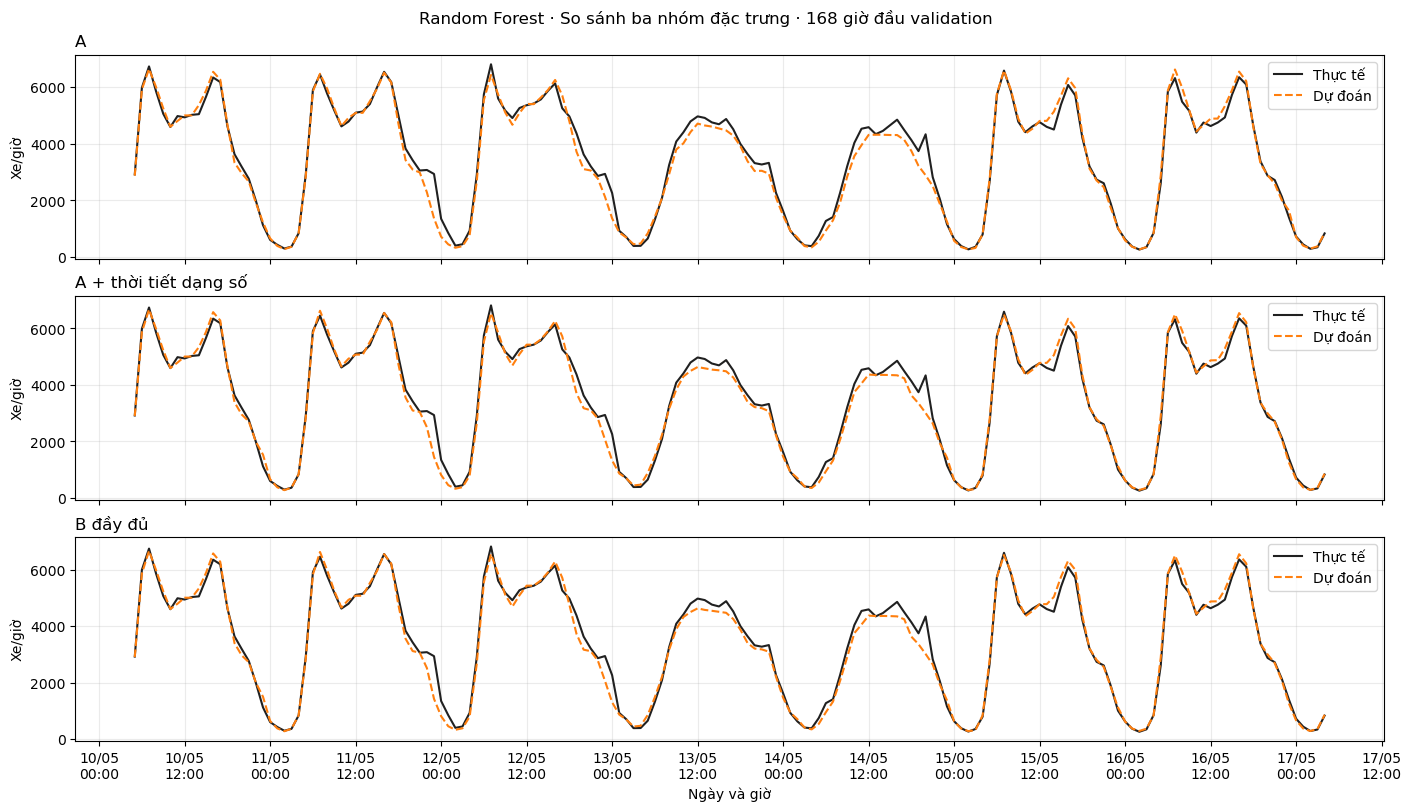

In [21]:
if RUN_VALIDATION:
    import matplotlib.dates as mdates
    import matplotlib.pyplot as plt

    HOURS_TO_PLOT = 7 * 24
    plot_index = pd.date_range(
        start=predictions["date_time"].min(), periods=HOURS_TO_PLOT, freq="h",
    )
    plot_data = predictions.set_index("date_time").reindex(plot_index)
    titles = {"A": "A", "A_numeric": "A + thời tiết dạng số", "B": "B đầy đủ"}

    fig, axes = plt.subplots(
        len(CONFIG_FEATURES), 1,
        figsize=(14, 8), sharex=True, sharey=True, layout="constrained",
    )
    for ax, config in zip(axes, CONFIG_FEATURES):
        ax.plot(plot_index, plot_data[TARGET], color="#202020", label="Thực tế")
        ax.plot(
            plot_index, plot_data[config], color="tab:orange",
            linestyle="--", label="Dự đoán",
        )
        ax.set_title(titles[config], loc="left")
        ax.set_ylabel("Xe/giờ")
        ax.grid(alpha=0.25)
        ax.legend(loc="upper right")

    axes[-1].set_xlabel("Ngày và giờ")
    axes[-1].xaxis.set_major_locator(mdates.HourLocator(byhour=[0, 12]))
    axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%d/%m\n%H:%M"))
    fig.suptitle("Random Forest · So sánh ba nhóm đặc trưng · 168 giờ đầu validation")

    image_dir = OUTPUT_DIR / "img"
    image_dir.mkdir(exist_ok=True)
    fig.savefig(image_dir / "config_b_weather_numeric_168h.png", dpi=300, facecolor="white")
    plt.show()

## Nhận xét sau khi chạy

Lần chạy `20261117_141557_451140` dùng cùng bộ tham số Random Forest cho ba phương án. CV gồm ba fold theo thời gian. Validation chấm trên cùng **6.086 giờ**, trong đó có **1.091 giờ cao điểm**. MAE và RMSE có đơn vị xe/giờ.

| Phương án | MAE fold 1 | MAE fold 2 | MAE fold 3 | MAE CV | MAE validation | RMSE validation | MAE cao điểm validation |
|---|---:|---:|---:|---:|---:|---:|---:|
| A | **254,75** | 274,52 | 312,58 | **280,62** | 241,97 | **380,94** | 360,59 |
| A + thời tiết dạng số | 266,37 | 266,10 | 313,73 | 282,07 | 242,27 | 397,21 | 359,70 |
| B đầy đủ | 266,83 | **265,30** | **311,72** | 281,28 | **240,10** | 395,49 | **354,09** |


**Kết luận:** với Random Forest hiện tại, bốn biến dạng số chưa giúp giảm MAE chung. B đầy đủ cho MAE validation và MAE giờ cao điểm thấp nhất, còn A dẫn về MAE CV và RMSE validation.